In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from main import SimulationType

df = pd.read_parquet(
    "screening_results",
)
print(df.shape[0])
df


14634


,index,doi,title,abstract,incl,work_id,publication_year,sim_seen,sim_seen_in_update,random_sample,p_score,batch_number,id,review_update,texts,sim_order,prediction,run_id,dataset_name,simulation_type
0,2733,https://doi.org/10.1038/npp.2011.72,The ZNF804A Gene: Characterization of a Novel ...,Schizophrenia and bipolar disorder share genet...,0,W2031207317,0.000062,1,NaN,1,NaN,None,2733,0,The ZNF804A Gene: Characterization of a Novel ...,131.0,NaN,1,Bos_2018,BASELINE
1,1975,https://doi.org/10.2967/jnumed.114.149229,Cortical Laminar Binding of PET Amyloid and Ta...,Neurofibrillary tau pathology and amyloid β (A...,0,W2107525575,0.000393,1,NaN,0,NaN,None,1975,0,Cortical Laminar Binding of PET Amyloid and Ta...,1236.0,0.000571,1,Bos_2018,BASELINE
2,3265,https://doi.org/10.17116/jnevro20171178111-17,Clinical and neurovisualization characteristic...,To study apathetic depression first diagnosed ...,0,W2753772499,0.000439,1,NaN,0,NaN,None,3265,0,Clinical and neurovisualization characteristic...,1497.0,0.000353,1,Bos_2018,BASELINE
3,1078,https://doi.org/10.1002/jnr.1242,Neurofilament protein in cerebrospinal fluid: ...,The objective of this study was to compare cer...,0,W1977206425,0.000916,1,NaN,1,NaN,None,1078,0,Neurofilament protein in cerebrospinal fluid: ...,115.0,NaN,1,Bos_2018,BASELINE
4,1054,https://doi.org/10.1159/000088248,Validating the DemTect with 18-Fluoro-2-Deoxy-...,&lt;i&gt;Objectives:&lt;/i&gt; The first study...,0,W2094572948,0.001013,1,NaN,0,NaN,None,1054,0,Validating the DemTect with 18-Fluoro-2-Deoxy-...,1363.0,0.000435,1,Bos_2018,BASELINE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14629,1170,https://doi.org/10.1002/(sici)1099-1166(199912...,Risk factors accelerating cerebral degenerativ...,Factors accelerating cerebral degenerative cha...,0,W2161198266,0.999079,1,2.0,0,NaN,None,1170,2,Risk factors accelerating cerebral degenerativ...,3505.0,0.002808,1,Bos_2018,REORDERING
14630,410,https://doi.org/10.1136/jnnp.2008.158881,White matter hyperintensities and medial tempo...,Clinical subtypes of mild cognitive impairment...,0,W2171487159,0.999189,0,NaN,0,NaN,None,410,2,White matter hyperintensities and medial tempo...,NaN,0.000789,1,Bos_2018,REORDERING
14631,4416,https://doi.org/10.1016/j.jalz.2014.11.003,Statins and brain integrity in older adults: S...,We examined whether statins are associated wit...,0,W1992798117,0.999292,1,2.0,0,NaN,None,4416,2,Statins and brain integrity in older adults: S...,3396.0,0.001878,1,Bos_2018,REORDERING
14632,4500,https://doi.org/10.1161/strokeaha.107.501106,Unrecognized Myocardial Infarction in Relation...,"Background and Purpose— Men, but not women, wi...",0,W1985920977,0.999404,1,2.0,0,NaN,None,4500,2,Unrecognized Myocardial Infarction in Relation...,3226.0,0.002310,1,Bos_2018,REORDERING


/tmp/ipykernel_2359360/3792190978.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for dataset, dgroup in df.groupby("dataset_name"):
/tmp/ipykernel_2359360/3792190978.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for i, (sim_type, sgroup) in enumerate(dgroup.groupby("simulation_type")):


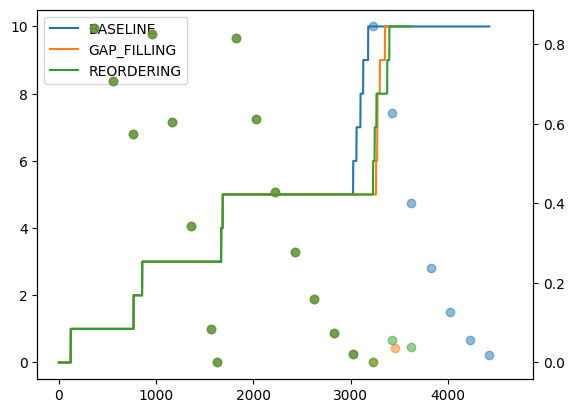

In [2]:
for dataset, dgroup in df.groupby("dataset_name"):
    fig, ax = plt.subplots()
    ax2 = ax.twinx()
    for i, (sim_type, sgroup) in enumerate(dgroup.groupby("simulation_type")):
        sgroup = sgroup.sort_values("sim_order").reset_index(drop=True)
        #ax.set_title(str(sim_type))
        ax.plot(sgroup["sim_order"], sgroup["incl"].cumsum(), color=f"C{i}", label=sim_type)
        ax2.scatter(sgroup["sim_order"], sgroup["p_score"], color=f"C{i}", alpha=0.5)
        ax.set_xlim(xmax=sgroup.shape[0])

    ax.legend()
    plt.show()



/tmp/ipykernel_2359360/3874760425.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for dataset, dgroup in df.groupby("dataset_name"):
/tmp/ipykernel_2359360/3874760425.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for i, (sim_type, sgroup) in enumerate(dgroup.groupby("simulation_type")):


,dataset,simulation_type,review_update,savings,recall
0,Bos_2018,BASELINE,0,0.000000,1.0
1,Bos_2018,BASELINE,1,0.050123,1.0
2,Bos_2018,BASELINE,2,0.092661,1.0
3,Bos_2018,GAP_FILLING,0,0.000000,1.0
4,Bos_2018,GAP_FILLING,1,0.000000,1.0
5,Bos_2018,GAP_FILLING,2,0.292333,1.0
6,Bos_2018,REORDERING,0,0.000000,1.0
7,Bos_2018,REORDERING,1,0.007688,1.0
8,Bos_2018,REORDERING,2,0.256663,1.0


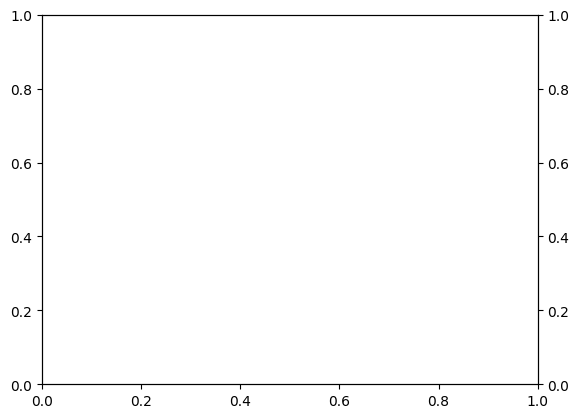

In [11]:
results_table = []
for dataset, dgroup in df.groupby("dataset_name"):
    fig, ax = plt.subplots()
    ax2 = ax.twinx()
    for i, (sim_type, sgroup) in enumerate(dgroup.groupby("simulation_type")):

        for review_update in [0,1,2]:
            update_sgroup = sgroup[sgroup["review_update"]<=review_update]
            n_seen = update_sgroup["sim_seen"].sum()
            savings = 1 - n_seen / update_sgroup.shape[0]
            recall = update_sgroup[update_sgroup["sim_seen"]==1]["incl"].sum() / update_sgroup["incl"].sum()
            results_table.append({
                "dataset": dataset,
                "simulation_type": sim_type,
                "review_update": review_update,
                "savings": savings,
                "recall": recall
            })

pd.DataFrame(results_table)

In [3]:
sgroup[
    sgroup["sim_seen"]==1 
]

,index,doi,title,abstract,incl,work_id,publication_year,sim_seen,sim_seen_in_update,random_sample,p_score,batch_number,id,review_update,texts,sim_order,prediction,run_id,dataset_name,simulation_type
0,2911,https://doi.org/10.1159/000289813,Combined Effect of Cerebral Hypoperfusion and ...,&lt;i&gt;Background/Aims:&lt;/i&gt; It has bee...,0,W1965052624,0.217470,1,NaN,1,NaN,None,2911,0,Combined Effect of Cerebral Hypoperfusion and ...,1.0,1.000000,1,Bos_2018,REORDERING
1,1033,https://doi.org/10.1111/j.1440-1819.1995.tb019...,Magnetic resonance imaging study of the brain ...,The aims of the present study were to clarify ...,0,W2018044446,0.259198,1,NaN,1,NaN,None,1033,0,Magnetic resonance imaging study of the brain ...,2.0,1.000000,1,Bos_2018,REORDERING
2,58,https://doi.org/10.1016/j.schres.2004.02.011,Volume of the cingulate and outcome in schizop...,Previous studies indicated that schizophrenia ...,0,W2077312665,0.121727,1,NaN,1,NaN,None,58,0,Volume of the cingulate and outcome in schizop...,3.0,1.000000,1,Bos_2018,REORDERING
3,2802,https://doi.org/10.1161/01.str.21.8.1143,Frontal white matter lesions and dementia in l...,We studied the associations of mental deterior...,0,W2069153487,0.299251,1,NaN,1,NaN,None,2802,0,Frontal white matter lesions and dementia in l...,4.0,1.000000,1,Bos_2018,REORDERING
4,1650,https://doi.org/10.1055/s-2007-1002278,Zur Frage der Multiinfarktdemenz unter besonde...,Multiinfarct- or vascular dementia can primari...,0,W2412159591,0.041298,1,NaN,1,NaN,None,1650,0,Zur Frage der Multiinfarktdemenz unter besonde...,5.0,1.000000,1,Bos_2018,REORDERING
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3621,2726,https://doi.org/10.1371/journal.pone.0172484,Impact of frontal white matter hyperintensity ...,Instrumental activities of daily living (IADL)...,0,W2591660649,0.688991,1,2.0,0,NaN,None,2726,2,Impact of frontal white matter hyperintensity ...,3621.0,0.001871,1,Bos_2018,REORDERING
3622,4315,https://doi.org/10.1159/000110364,Agreement in the Clinical Diagnosis of Dementi...,Interobserver agreement in the clinical diagno...,0,W2035795330,0.776055,1,2.0,0,NaN,None,4315,2,Agreement in the Clinical Diagnosis of Dementi...,3622.0,0.001870,1,Bos_2018,REORDERING
3623,2129,https://doi.org/10.1016/j.pscychresns.2010.07.005,MRI correlates of episodic memory in Alzheimer...,Episodic memory is a core feature of Alzheimer...,0,W2154749730,0.792686,1,2.0,0,NaN,None,2129,2,MRI correlates of episodic memory in Alzheimer...,3623.0,0.001868,1,Bos_2018,REORDERING
3624,1920,None,Analysis of correlation between the degree of ...,The aim of the study was to assess the relatio...,0,W2413315429,0.917218,1,2.0,0,NaN,None,1920,2,Analysis of correlation between the degree of ...,3624.0,0.001867,1,Bos_2018,REORDERING


In [4]:
sgroup.shape

(4878, 20)

In [5]:
interim_df = pd.read_parquet(
    "interim-screening-results",
)
interim_df = interim_df[
    (df["dataset_name"] == dataset) & 
    (df["simulation_type"] == "REORDERING")
]



/tmp/ipykernel_2359360/1156184409.py:4: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  interim_df = interim_df[


IndexingError: Unalignable boolean Series provided as indexer (index of the boolean Series and of the indexed object do not match).